# Figure partitioning reanalysis uncertainty between impact model fitting and BCDS process

In [112]:
import xarray as xr
import numpy as np
import pandas as pd
import geopandas as gpd
from matplotlib import pyplot as plt
from matplotlib import patches as mpatches
import matplotlib as mpl
from cartopy import crs as ccrs
import cmocean
import seaborn as sns
import warnings

import os
import glob
import re

from funcs_support import get_filepaths,get_params,utility_save,utility_print,load_shp
from funcs_plot import add_colorbar
dir_list = get_params()
dir_list['aux_bigmem'] = '/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/'

extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}


In [10]:
from distributed import Client

# Start dask client 
# (playing around with workers, threads for efficiency)
client = Client(n_workers=6,
    threads_per_worker=3,
    processes=True,
    memory_limit="8GB")
display(client)

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 33719 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/33719/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/33719/status,Workers: 6
Total threads: 18,Total memory: 44.70 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:33229,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/33719/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:37329,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/35899/status,Memory: 7.45 GiB
Nanny: tcp://127.0.0.1:36623,


2026-04-14 12:43:31,126 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle a64114f5305316293f9a12d5e4324deb initialized by task ('rechunk-merge-rechunk-transfer-485f6482c63eda13ea6b8bfe8b59e275', 0, 0, 0, 7, 0, 0, 0, 0, 0, 7, 0, 4) executed on worker tcp://127.0.0.1:38183
2026-04-14 12:43:32,887 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle edac27f55aff4049605b6f84788e34f0 initialized by task ('rechunk-merge-rechunk-transfer-485f6482c63eda13ea6b8bfe8b59e275', 0, 0, 0, 6, 0, 0, 0, 0, 0, 6, 0, 9) executed on worker tcp://127.0.0.1:42913
2026-04-14 12:43:33,373 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle a64114f5305316293f9a12d5e4324deb deactivated due to stimulus 'task-finished-1776192213.3719518'
2026-04-14 12:43:35,066 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle b3c938bf7fbda3f94f3c97865b38a375 initialized by task ('rechunk-merge-rechunk-transfer-485f6482c63eda13ea6b8bfe8b59e275', 0, 0, 0, 5, 0, 0, 0, 0, 0, 5, 0, 9) executed on wor

In [11]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'days90plus','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}



In [12]:
def load_impacts(proc,uncert_typ,return_maxgwl = False,return_crossfits=False):
    '''
    NOTE: MAX_GWL IS HARDCODED HERE
    '''
    
    # Load impacts projections
    if return_crossfits:
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}-cross*.zarr'))
    else:
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_*.zarr'))
    def load_impact(fn):
        ds_tmp = xr.open_zarr(fn,consolidated=False)
        ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
        ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
    
        ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
        ds_tmp = ds_tmp.reset_index('idv')
        ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        return ds_tmp
    
    with warnings.catch_warnings():
        # Silence zarr warnings related to the /.done flags used
        warnings.filterwarnings('ignore')
        dss = xr.concat([load_impact(fn) for fn in fns],
                    dim='idv',join='outer')
    
    dss = dss.set_index({'poly_idx':'locid'}).rename({'poly_idx':'locid'})

    if return_maxgwl:
        return dss.maxgwl
    
    # Figure out how many BCD-ME members reach a given GWL
    gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
    gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
    #print(gwl_counter)
    
    dss_tmp = dss
    
    if 'noMERRA2' in uncert_typ:
        dss_tmp = dss_tmp.sel(proj_base = [pb for pb in dss_tmp.proj_base.values if pb != 'MERRA2'])
    
    if re.search(r'[0-9].*runs[0-9].*mods',uncert_typ):
        max_gwl = 3
        nruns = int(re.split('runs',uncert_typ)[0])
        
        gwlmods = gwl_counter.sel(maxgwl=max_gwl)
        proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
        
        dss_tmp = dss_tmp.isel(idv = dss.maxgwl>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
        dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})

    for v in ['experiment','run']:
        dss_tmp[v] = dss_tmp[v].astype(object)
    dss_tmp = dss_tmp.unstack('idv')['d'+proc]
    #dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})

    return dss_tmp

In [149]:
obsuncs_all = {}
overwrite = False
for proc in params_proc:
    tmp_fn1 = f'{dir_list['aux_bigmem']}crossfit_{proc}_rechk_tmp1.zarr'
    tmp_fn2 = f'{dir_list['aux_bigmem']}crossfit_{proc}_rechk_tmp2.zarr'
    if overwrite or (not os.path.exists(tmp_fn2)):
        dss = load_impacts(proc,'allruns',return_crossfits=True)
        dss = dss.chunk({'gwl':1,'fit_mod':-1,'proj_base':-1,'locid':5000})
        # Save rechunked as temporary file
        
        utility_save(dss,tmp_fn1,zarr_mode='w')
        dss = xr.open_zarr(tmp_fn1)
        dss = dss.chunk({'gwl':1,'fit_mod':-1,'proj_base':-1,'locid':200,'exprun':-1,'model':-1})
        
        utility_save(dss.drop_encoding(),tmp_fn2,zarr_mode='w')
        os.system('rm -rf '+tmp_fn1)
    dss = xr.open_zarr(tmp_fn2)

    #problem_runs = [{'model':'IPSL-CM6A-LR','exprun':'ssp370r6i1p1f1'},
    #                {'model':'MPI-ESM1-2-LR','exprun':'ssp370r9i1p1f1'}]
    #for problem_run in problem_runs:
    #    dss = dss.where(~((dss.model == problem_run['model']) & 
    #            (dss.exprun == problem_run['exprun'])))

    fit_mods = ['ERA5','MERRA2','JRA-3Q','GMFD']


    obsuncs_all[proc] = xr.merge([dss.sel(fit_mod=fit_mods).mean('fit_mod').var('proj_base').mean('exprun').mean('model').compute().rename({'d'+proc:'bcds'}),
                                    dss.sel(fit_mod=fit_mods).var('fit_mod').mean('proj_base').mean('exprun').mean('model').compute().rename({'d'+proc:'impmod'}),
                                  dss.sel(fit_mod=fit_mods).mean('fit_mod').mean('proj_base').var('exprun').mean('model').compute().rename({'d'+proc:'uncint'}),
                                  dss.sel(fit_mod=fit_mods).mean('fit_mod').mean('proj_base').mean('exprun').var('model').compute().rename({'d'+proc:'uncmod'})],
                                   compat = 'no_conflicts')

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure4.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure4.png saved!


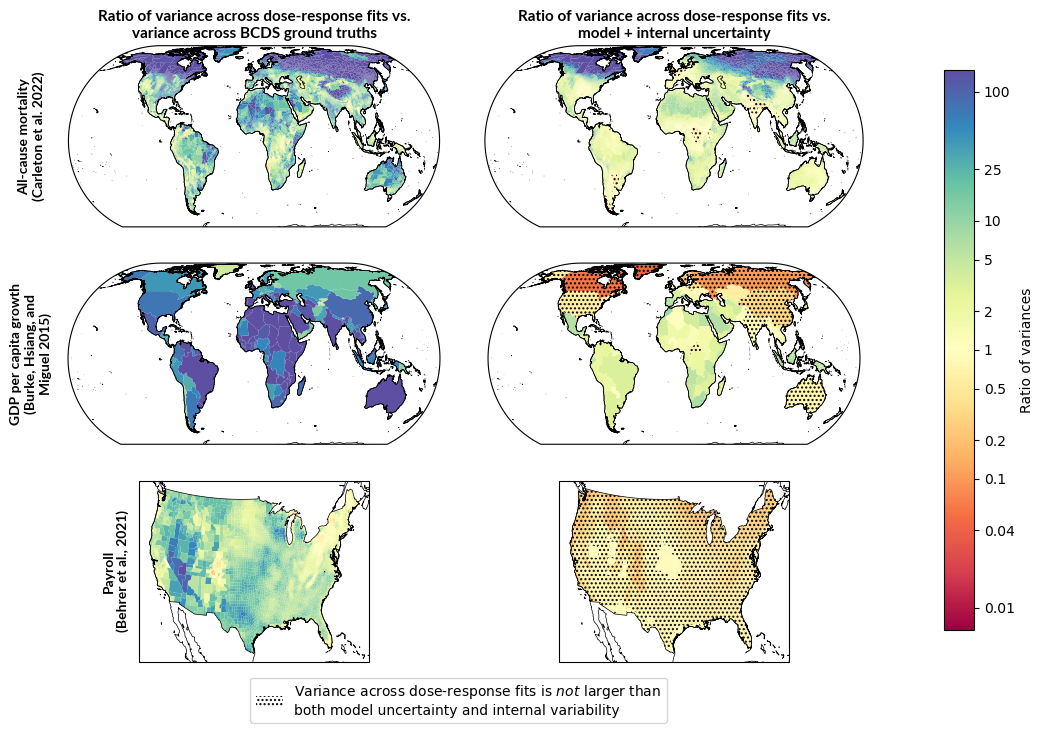

In [160]:
save_fig = True
output_fn = dir_list['figs']+'Figure4'

fig = plt.figure(figsize=(12,8))

gwl = 2

idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke, Hsiang, and\nMiguel 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}

indflag = 'noInd'

cbar_params = {'cmap':'Spectral','vmin':-5,'vmax':5}

projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

for row_idx,proc in enumerate(params_proc):
    # Load shapefile
    gdf = load_shp(proc)

    if proc == 'mortality':
        df_obsuncs = obsuncs_all[proc].sel(indflag = indflag).to_dataframe().reset_index().set_index(['gwl','locid']).sort_index()
    else:
        df_obsuncs = obsuncs_all[proc].to_dataframe().reset_index().set_index(['gwl','locid']).sort_index()
        
    ratio_to_bcds = np.log(df_obsuncs.loc[gwl]['impmod'] / df_obsuncs.loc[gwl]['bcds'])
    ratio_to_bcds.name= 'impmod_to_bcds'
    ratio_to_intmod = np.log(df_obsuncs.loc[gwl]['impmod'] / (df_obsuncs.loc[gwl]['uncint'] + 
                                                                         df_obsuncs.loc[gwl]['uncmod']))
    ratio_to_intmod.name= 'impmod_to_intmod'
    
    ratios = pd.merge(ratio_to_bcds,ratio_to_intmod,left_index=True,right_index=True)
    ratios.index = ratios.index.set_names(list(idxs[params_proc[proc]['geo_typ']].values())[0])

    gdf = gdf.join(ratios,on=list(idxs[params_proc[proc]['geo_typ']].values())[0])

    #----- Plot of ratio of model training to BCDS
    ax = plt.subplot(3,2,2*row_idx+1,projection=projs[proc])

    # Plot 
    gdf.plot(column='impmod_to_bcds',**cbar_params,
            ax=ax,transform=ccrs.PlateCarree())
    gdf.dissolve().plot(facecolor='none',edgecolor='k',ax=ax,transform=ccrs.PlateCarree(),
                        linewidth=0.5)
    ax.coastlines(linewidth=0.5)

    if row_idx == 0:
        ax.set_title('Ratio of variance across dose-response fits vs.\nvariance across BCDS ground truths',
                     font = extra_fonts['lato-bold'],fontsize=11)
    else:
        ax.set_title('')

    # Row labels
    ax.annotate(proc_full_names[proc],
                (-0.1,0.5),xycoords = 'axes fraction',
                fontweight='bold',fontsize=10,va='center',ha='center',
                rotation=90,font=extra_fonts['lato-bold'])

    #----- Plot of ratio of model training to mod + int
    ax = plt.subplot(3,2,2*row_idx+2,projection=projs[proc])

    # Plot
    gdf.plot(column='impmod_to_intmod',**cbar_params,
            ax=ax,transform=ccrs.PlateCarree())
    gdf.dissolve().plot(facecolor='none',edgecolor='k',ax=ax,transform=ccrs.PlateCarree(),
                        linewidth=0.5)

    # Add hatching to areas where impmod is _not_ larger than both uncint or uncmod
    imp_largest_source = (df_obsuncs['impmod'] > df_obsuncs['uncint']) & (df_obsuncs['impmod'] > df_obsuncs['uncmod'])
    gdf.set_index('locid').where(~imp_largest_source.loc[gwl]).dropna(how='all').dissolve().plot(hatch='....',facecolor='none',linewidth=0,
                                                                                        transform=ccrs.PlateCarree(),
                                                                                        ax=ax)
    
    ax.coastlines(linewidth=0.5)

    if row_idx == 0:
        ax.set_title('Ratio of variance across dose-response fits vs.\nmodel + internal uncertainty',
                    font = extra_fonts['lato-bold'],fontsize=11)
    else:
        ax.set_title('')

    if row_idx == len(params_proc)-1:
        ax.legend(handles=[mpatches.Patch(facecolor='none', edgecolor='k', linewidth=0,
                                          hatch='....', 
                                          label=r'Variance across dose-response fits is $\it{not}$ larger than'+'\nboth model uncertainty and internal variability')],
                bbox_to_anchor = [0.5,-0.05],loc='upper center')

# Horizontal colorbar
fig.subplots_adjust(right=0.825,wspace=0)
cbar = add_colorbar(cbar_params,orientation='vertical',fig=fig,
                    label = 'Ratio of variances')
ticklocs = [1/100,1/25,1/10,1/5,1/2,1,2,5,10,25,100]
cbar.set_ticks([np.log(k) for k in ticklocs],
               labels=[str(k) for k in ticklocs])

if save_fig:
    utility_print(output_fn)
    

In [161]:
ax.legend?

Signature: ax.legend(*args, **kwargs)
Docstring:
Place a legend on the Axes.

Call signatures::

    legend()
    legend(handles, labels)
    legend(handles=handles)
    legend(labels)

The call signatures correspond to the following different ways to use
this method:

**1. Automatic detection of elements to be shown in the legend**

The elements to be added to the legend are automatically determined,
when you do not pass in any extra arguments.

In this case, the labels are taken from the artist. You can specify
them either at artist creation or by calling the
:meth:`~.Artist.set_label` method on the artist::

    ax.plot([1, 2, 3], label='Inline label')
    ax.legend()

or::

    line, = ax.plot([1, 2, 3])
    line.set_label('Label via method')
    ax.legend()

.. note::
    Specific artists can be excluded from the automatic legend element
    selection by using a label starting with an underscore, "_".
    A string starting with an underscore is the default label for all
    artist

In [ ]:
# Make the payroll figure span a little wider, so the aspect ratio fits better
                # with the global maps
                if proc == 'payroll':
                    ax_map.set_extent((-140, -64, 23.7, 50.6),
                              crs = ccrs.PlateCarree())

In [75]:
imp_largest_source = (df_obsuncs['impmod'] > df_obsuncs['uncint']) & (df_obsuncs['impmod'] > df_obsuncs['uncmod'])
    